# Chapter-11: Tools & Model Context Protocol (MCP)

# <font color="#800000">Working With Tools In LangChain And LangGraph</font>

## <font color="#3366FF">Tool Creation</font>

### Example Of Tool Creation

In [2]:
import random
from langchain.tools import tool

@tool
def stock_price(name: str) -> int:
    """
    Fetches the current market price of a stock.

    Parameters
    ----------
    name: str
        The name of the stock.

    Returns
    -------
    float
        The current stock price (in USD).
    """
    price = round(random.uniform(10, 500), 2)
    return price


In [3]:
type(stock_price)

langchain_core.tools.structured.StructuredTool

In [4]:
stock_price

StructuredTool(name='stock_price', description='Fetches the current market price of a stock.\n\nParameters\n----------\nname: str\n    The name of the stock.\n\nReturns\n-------\nfloat\n    The current stock price (in USD).', args_schema=<class 'langchain_core.utils.pydantic.stock_price'>, func=<function stock_price at 0x11b5d4040>)

### Invoking Tool

In [5]:
## Invoke Tool        
stock_price.invoke('Apple')


186.91

## <font color="#3366FF">Tool Calling</font>

### Example Of Tool Calling

In [6]:
import os
import random
import json
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langchain.tools import tool


## Loading OpenAI API key from env file into an environment variable
load_dotenv()
os.environ["OPENAI_API_KEY"] = os.getenv('OPENAI_API_KEY')

## Initialize ChatOpenAI LLM
llm = ChatOpenAI(model="gpt-5-mini")

### Defining All Tools Here 

@tool
def stock_price(name: str) -> int:
    """
    Fetches the current market price of a stock.

    Parameters
    ----------
    name : str
        The name of the stock.

    Returns
    -------
    float
        The current stock price (in USD).
    """
    price = round(random.uniform(10, 500), 2)
    return price

@tool
def buy_stock(name: str, qty: int) -> str:
    """
    This function buys a specific quantity of a stock.

    Parameters
    ----------
    name : str
        The name of the stock to buy.

    qty : int
        The number of shares to purchase.

    Returns
    -------
    str
        Feedback on stock purchase success or failure.
    """
    return f"Successfully purchased {qty} shares of {name}."

@tool
def sell_stock(name: str, qty: int) -> str:
    """
    This function sells a specific quantity of a stock.

    Parameters
    ----------
    name : str
        The name of the stock to sell.

    qty : int
        The number of shares to sell.

    Returns
    -------
    str
        Feedback on the stock sales success or failure.
    """
    return f"Successfully sold {qty} shares of {name}."

## Create Tool List
tools = [stock_price, buy_stock, sell_stock]

## Bind List of Tools with LLM
llm_with_tools = llm.bind_tools(tools)

## Invoke LLM with Tools
response = llm_with_tools.invoke("Sell 25 Apple shares from my portfolio")

## Response Output
response


AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 91, 'prompt_tokens': 317, 'total_tokens': 408, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-EYuRNQb7LrlnONVmU4agZXkef81Hn', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a13adb-5d7b-7e31-8473-a10360b2225d-0', tool_calls=[{'name': 'sell_stock', 'args': {'name': 'Apple', 'qty': 25}, 'id': 'call_hycCMhWzxQlQ3OWKXK6KWxAN', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 317, 'output_tokens': 91, 'total_tokens': 408, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 64}})

In [7]:
print("\ncontent:")
print(response.content)

print("\ntool_calls:")
print(json.dumps(response.tool_calls, indent=2))



content:


tool_calls:
[
  {
    "name": "sell_stock",
    "args": {
      "name": "Apple",
      "qty": 25
    },
    "id": "call_hycCMhWzxQlQ3OWKXK6KWxAN",
    "type": "tool_call"
  }
]


### Multiple Tool Calls

In [8]:
## Invoke LLM with Tools
response = llm_with_tools.invoke("Sell 25 Apple shares from my portfolio and purchase 10 Microsoft stocks")

print("\ncontent:")
print(response.content)

print("\ntool_calls:")
print(json.dumps(response.tool_calls, indent=2))



content:


tool_calls:
[
  {
    "name": "sell_stock",
    "args": {
      "name": "Apple",
      "qty": 25
    },
    "id": "call_c2ivRmuJDcVOWa20oW99lbjk",
    "type": "tool_call"
  },
  {
    "name": "buy_stock",
    "args": {
      "name": "Microsoft",
      "qty": 10
    },
    "id": "call_WKAdrErR7KWx1vRjeZHrNgPg",
    "type": "tool_call"
  }
]


### No Tool Call Scenario

In [9]:
## Invoke LLM with Tools
response = llm_with_tools.invoke("What is PE ratio in stocks? Explain in one line")

print("\ncontent:")
print(response.content)

print("\ntool_calls:")
print(json.dumps(response.tool_calls, indent=2))



content:
P/E (price-to-earnings) ratio is a valuation metric equal to a company's current share price divided by its earnings per share (EPS), showing how much investors pay for each dollar of earnings.

tool_calls:
[]


## <font color="#3366FF">Tool Execution With LangChain</font>

### Understanding Basics With Manual Approach

In [10]:
## ...(LLM and Tool Initialization same as above)...

## Create Tool List
tools = [stock_price, buy_stock, sell_stock]

## Bind List of Tools with LLM
llm_with_tools = llm.bind_tools(tools)

## Invoke LLM with Tools
response = llm_with_tools.invoke("Sell 25 Apple shares from my portfolio")

## Get Tool Calls Details
tool_call_details = response.tool_calls

## Print Tool Call Details
print(tool_call_details)


[{'name': 'sell_stock', 'args': {'name': 'Apple', 'qty': 25}, 'id': 'call_cruW1c2ENQZNU7jvU1v6iooq', 'type': 'tool_call'}]


In [11]:
## Extract Arguments
arguments = tool_call_details[0]['args']

## Invoke Tool with Arguments
sell_stock.invoke(arguments)


'Successfully sold 25 shares of Apple.'

#### Generating ToolMessage

In [12]:
## Invoke Tool with Tool Call Details
sell_stock.invoke(tool_call_details[0])


ToolMessage(content='Successfully sold 25 shares of Apple.', name='sell_stock', tool_call_id='call_cruW1c2ENQZNU7jvU1v6iooq')

### Generalised Tool Execution Solution

#### Step 1: Add Tool Dictionary For Lookup

In [13]:
## ...(LLM and Tool Initialization same as earlier)...

## Create Tool List
tools = [stock_price, buy_stock, sell_stock]

## Bind List of Tools with LLM
llm_with_tools = llm.bind_tools(tools)

## Create Dictionary of Tools for Lookup
tools_dictionary= {tool.name: tool for tool in tools}

## Invoke LLM with Tools
response = llm_with_tools.invoke("Buy 25 Google shares from my portfolio")

## Fetch Tool from Dictionary
tool_fn = tools_dictionary[response.tool_calls[0]["name"]]

## Invoke Tool
tool_fn.invoke(response.tool_calls[0])


ToolMessage(content='Successfully purchased 25 shares of Google.', name='buy_stock', tool_call_id='call_5QlGOdtFMXkG4a0DLutMvzCX')

In [14]:
tools_dictionary

{'stock_price': StructuredTool(name='stock_price', description='Fetches the current market price of a stock.\n\nParameters\n----------\nname : str\n    The name of the stock.\n\nReturns\n-------\nfloat\n    The current stock price (in USD).', args_schema=<class 'langchain_core.utils.pydantic.stock_price'>, func=<function stock_price at 0x11c2376a0>),
 'buy_stock': StructuredTool(name='buy_stock', description='This function buys a specific quantity of a stock.\n\nParameters\n----------\nname : str\n    The name of the stock to buy.\n\nqty : int\n    The number of shares to purchase.\n\nReturns\n-------\nstr\n    Feedback on stock purchase success or failure.', args_schema=<class 'langchain_core.utils.pydantic.buy_stock'>, func=<function buy_stock at 0x11c2ebe20>),
 'sell_stock': StructuredTool(name='sell_stock', description='This function sells a specific quantity of a stock.\n\nParameters\n----------\nname : str\n    The name of the stock to sell.\n\nqty : int\n    The number of shares

#### Step 2: Add Support For Multiple Tools Execution

In [15]:
## ...(LLM and Tool Initialization same as earlier)...

## Create Tool List
tools = [stock_price, buy_stock, sell_stock]

## Bind List of Tools with LLM
llm_with_tools = llm.bind_tools(tools)

## Create Dictionary of Tools for Lookup
tools_dictionary= {tool.name: tool for tool in tools}

## Invoke LLM with Tools
response = llm_with_tools.invoke("Buy 25 and 19 shares of Google & Microsoft respectively and sale 5 stocks of Apple")

## Message List
messages = []

## Execute Tools One by One in Loop
for tool_call in response.tool_calls:

    ## Fetch Tool from Dictionary
    tool_fn = tools_dictionary[tool_call["name"]]

    ## Execute Tool
    tool_msg = tool_fn.invoke(tool_call)

    ## Append ToolMessage to messages list
    messages.append(tool_msg)

print(messages)


[ToolMessage(content='Successfully purchased 25 shares of Google.', name='buy_stock', tool_call_id='call_cRuEiJGUVkzkDlAiTiRSXVkW'), ToolMessage(content='Successfully purchased 19 shares of Microsoft.', name='buy_stock', tool_call_id='call_zSGcHH8tsts0I5RtseNwWHCp'), ToolMessage(content='Successfully sold 5 shares of Apple.', name='sell_stock', tool_call_id='call_tcfGqByegLX61bsHIDN7GSG2')]


#### Step 3: Add Support For Non-Tool Calling Scenario

In [16]:
## ...(LLM and Tool Initialization same as earlier)...

## Create Tool List
tools = [stock_price, buy_stock, sell_stock]

## Bind List of Tools with LLM
llm_with_tools = llm.bind_tools(tools)

## Create Dictionary of Tools for Lookup
tools_dictionary= {tool.name: tool for tool in tools}

## Invoke LLM with Tools
response = llm_with_tools.invoke("Explain P/E Ratio in one line")

## Message List
messages = []

## Check if LLM response has any tool_calls field
if hasattr(response, "tool_calls") and response.tool_calls:
    
    ## Execute Tools One by One in Loop
    for tool_call in response.tool_calls:

        ## Fetch Tool from Dictionary
        tool_fn = tools_dictionary[tool_call["name"]]

        ## Execute Tool
        tool_msg = tool_fn.invoke(tool_call)

        ## Append ToolMessage to messages list
        messages.append(tool_msg)

else:
    ## No tool calls, add the AIMessage to the messages list
    messages.append(response)

print(messages)


[AIMessage(content="P/E ratio (price-to-earnings) = current share price ÷ earnings per share, showing how much investors pay for each dollar of a company's earnings.", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 106, 'prompt_tokens': 316, 'total_tokens': 422, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-EYuRa6RE9KT8x9qT2PFdtSQYj5iE4', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a13adb-8dd5-77a0-aa95-970dbc4b5159-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 316, 'output_tokens': 106, 'total_tokens': 422, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoni

## <font color="#3366FF">Tool Execution With LangGraph</font>

### Step 1: Create Tool Calling LLM Node

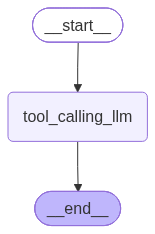

================================ Human Message =================================

Buy 19 shares of Microsoft and sell 5 stocks of Apple
================================== Ai Message ==================================
Tool Calls:
  buy_stock (call_05NtfDryUI5PlSBvW5HvrZcg)
 Call ID: call_05NtfDryUI5PlSBvW5HvrZcg
  Args:
    name: Microsoft
    qty: 19
  sell_stock (call_w4gElzmBEm2w4CDUMDaTMyiy)
 Call ID: call_w4gElzmBEm2w4CDUMDaTMyiy
  Args:
    name: Apple
    qty: 5


In [17]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END, MessagesState
from langchain.messages import HumanMessage

## ...(LLM and Tool Initialization same as earlier)...

## Create Tool List
tools = [stock_price, buy_stock, sell_stock]

## Bind List of Tools with LLM
llm_with_tools = llm.bind_tools(tools)
    
## Tool Calling Node
def tool_calling_llm(state: MessagesState):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Initialize StateGraph with MessagesState
graph_builder = StateGraph(MessagesState)

## Add Node to StateGraph
graph_builder.add_node("tool_calling_llm", tool_calling_llm)

## Add Edges to StateGraph
graph_builder.add_edge(START, "tool_calling_llm")
graph_builder.add_edge("tool_calling_llm", END)

## Compile Graph
graph = graph_builder.compile()

## Visualize Graph
display(Image(graph.get_graph().draw_mermaid_png()))

## Invoke Graph
messages = graph.invoke({"messages": HumanMessage(content="Buy 19 shares of Microsoft and sell 5 stocks of Apple")})

## Print Messages
for m in messages['messages']:
    m.pretty_print()


### Step 2: Add ToolNode For Tool Execution

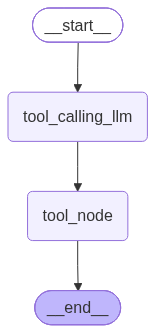

================================ Human Message =================================

Buy 19 shares of Microsoft and sell 5 stocks of Apple
================================== Ai Message ==================================
Tool Calls:
  buy_stock (call_lg8KEZsvv48rn3hyWerh5Mr3)
 Call ID: call_lg8KEZsvv48rn3hyWerh5Mr3
  Args:
    name: Microsoft
    qty: 19
  sell_stock (call_DT6HBs47vpm2PQtAwKxdYPAO)
 Call ID: call_DT6HBs47vpm2PQtAwKxdYPAO
  Args:
    name: Apple
    qty: 5
================================= Tool Message =================================
Name: buy_stock

Successfully purchased 19 shares of Microsoft.
================================= Tool Message =================================
Name: sell_stock

Successfully sold 5 shares of Apple.


In [18]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.graph import MessagesState
from langchain.messages import HumanMessage

## ...(LLM and Tool Initialization same as earlier)...

## Create Tool List
tools = [stock_price, buy_stock, sell_stock]

## Create Dictionary of Tools for Lookup
tools_dictionary= {tool.name: tool for tool in tools}

## Bind List of Tools with LLM
llm_with_tools = llm.bind_tools(tools)
    
## Tool Calling Node
def tool_calling_llm(state: MessagesState):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Tool Execution Node
def tool_node(state: MessagesState):

    result = []
    
    for tool_call in state["messages"][-1].tool_calls:
        
        ## Fetch Tool from Dictionary
        tool_fn = tools_dictionary[tool_call["name"]]

        ## Execute Tool
        tool_msg = tool_fn.invoke(tool_call)

        ## Append ToolMessage to messages list
        result.append(tool_msg)

    return {"messages": result}

## Initialize StateGraph with MessagesState
graph_builder = StateGraph(MessagesState)

## Add Node to StateGraph
graph_builder.add_node("tool_calling_llm", tool_calling_llm)
graph_builder.add_node("tool_node", tool_node)

## Add Edges to StateGraph
graph_builder.add_edge(START, "tool_calling_llm")
graph_builder.add_edge("tool_calling_llm", "tool_node")
graph_builder.add_edge("tool_node", END)

## Compile Graph
graph = graph_builder.compile()

## Visualize Graph
display(Image(graph.get_graph().draw_mermaid_png()))

## Invoke Graph
messages = graph.invoke({"messages": HumanMessage(content="Buy 19 shares of Microsoft and sell 5 stocks of Apple")})

## Print Messages
for m in messages['messages']:
    m.pretty_print()


### Step 3: Add Tools Condition

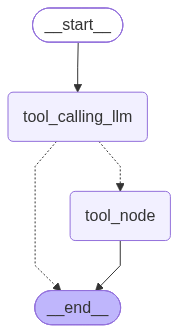

================================ Human Message =================================

Explain P/E Ratio in one line
================================== Ai Message ==================================

The price-to-earnings (P/E) ratio is the market price per share divided by earnings per share, showing how much investors pay for each dollar of a company's earnings.


In [19]:
from IPython.display import Image, display
from typing import Literal
from langgraph.graph import StateGraph, START, END
from langgraph.graph import MessagesState
from langchain.messages import HumanMessage

## ...(LLM and Tool Initialization same as earlier)...

## Create Tool List
tools = [stock_price, buy_stock, sell_stock]

## Create Dictionary of Tools for Lookup
tools_dictionary= {tool.name: tool for tool in tools}

## Bind List of Tools with LLM
llm_with_tools = llm.bind_tools(tools)
    
## Tool Calling Node
def tool_calling_llm(state: MessagesState):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Tool Execution Node
def tool_node(state: MessagesState):

    result = []
    
    for tool_call in state["messages"][-1].tool_calls:
        
        ## Fetch Tool from Dictionary
        tool_fn = tools_dictionary[tool_call["name"]]

        ## Execute Tool
        tool_msg = tool_fn.invoke(tool_call)

        ## Append ToolMessage to messages list
        result.append(tool_msg)

    return {"messages": result}

## Tool Execution Node
def check_tool_condition(state: MessagesState) -> Literal["tool_node", END]:

    ## Fetch last LLM message
    messages = state["messages"]
    last_message = messages[-1]

    ## If last LLM message contains a tool call, then goto tool_node
    if last_message.tool_calls:
        return "tool_node"

    ## Else goto END
    return END

## Initialize StateGraph with MessagesState
graph_builder = StateGraph(MessagesState)

## Add Node to StateGraph
graph_builder.add_node("tool_calling_llm", tool_calling_llm)
graph_builder.add_node("tool_node", tool_node)

## Add Edges to StateGraph
graph_builder.add_edge(START, "tool_calling_llm")
graph_builder.add_conditional_edges(
    "tool_calling_llm",
    check_tool_condition,
    ["tool_node", END]
)
graph_builder.add_edge("tool_node", END)

## Compile Graph
graph = graph_builder.compile()

## Visualize Graph
display(Image(graph.get_graph().draw_mermaid_png()))

## Invoke Graph
messages = graph.invoke({"messages": HumanMessage(content="Explain P/E Ratio in one line")})

## Print Messages
for m in messages['messages']:
    m.pretty_print()


### Tool Execution With Prebuilt LangGraph 

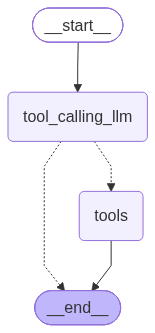

================================ Human Message =================================

Buy 19 shares of Microsoft and sell 5 stocks of Apple
================================== Ai Message ==================================
Tool Calls:
  buy_stock (call_NJeyEsHJsLaSWGKdWZ8V5TfI)
 Call ID: call_NJeyEsHJsLaSWGKdWZ8V5TfI
  Args:
    name: Microsoft
    qty: 19
  sell_stock (call_ygPQgPLOLcDMIhCODpMFXBJG)
 Call ID: call_ygPQgPLOLcDMIhCODpMFXBJG
  Args:
    name: Apple
    qty: 5
================================= Tool Message =================================
Name: buy_stock

Successfully purchased 19 shares of Microsoft.
================================= Tool Message =================================
Name: sell_stock

Successfully sold 5 shares of Apple.


In [20]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.graph import MessagesState
from langchain.messages import HumanMessage
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## ...(LLM and Tool Initialization same as earlier)...

## Create Tool List
tools = [stock_price, buy_stock, sell_stock]

## Bind List of Tools with LLM
llm_with_tools = llm.bind_tools(tools)
    
## Tool Calling Node
def tool_calling_llm(state: MessagesState):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Initialize StateGraph with MessagesState
graph_builder = StateGraph(MessagesState)

## Add Node to StateGraph
graph_builder.add_node("tool_calling_llm", tool_calling_llm)
graph_builder.add_node("tools", ToolNode(tools))

## Add Edges to StateGraph
graph_builder.add_edge(START, "tool_calling_llm")
graph_builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition,
)
graph_builder.add_edge("tools", END)

## Compile Graph
graph = graph_builder.compile()

## Visualize Graph
display(Image(graph.get_graph().draw_mermaid_png()))

## Invoke Graph
messages = graph.invoke({"messages": HumanMessage(content="Buy 19 shares of Microsoft and sell 5 stocks of Apple")})

## Print Messages
for m in messages['messages']:
    m.pretty_print()


## <font color="#3366FF">Built-In Tools In LangChain</font>

### Tavily Search Tool

#### Example

In [21]:
import os
import random
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langchain_tavily import TavilySearch

## Loading OpenAI API key from env file into an environment variable
load_dotenv()
os.environ["OPENAI_API_KEY"] = os.getenv('OPENAI_API_KEY')
os.environ['TAVILY_API_KEY'] = os.getenv("TAVILY_API_KEY")

## Initialize ChatOpenAI LLM
llm = ChatOpenAI(model="gpt-5-mini")

## Initialize Tavily Tool
tavily_tool = TavilySearch(max_results=5)

## Create Tool List
tools = [tavily_tool]

## Bind List of Tools with LLM
llm_with_tools = llm.bind_tools(tools)

## Invoke LLM with Tools
response = llm_with_tools.invoke("What is the current stock price of IBM?")

## Response Output
print(response.tool_calls)


[{'name': 'tavily_search', 'args': {'query': 'IBM stock price current', 'search_depth': 'fast', 'include_images': False, 'topic': 'finance'}, 'id': 'call_UGD3Km23d2cJovaJeL8hp3lq', 'type': 'tool_call'}]


# <font color="#800000">Working With MCP In LangChain</font>

## <font color="#3366FF">Creating MCP Servers With FastMCP</font>

### MCP Server With STDIO Protocol

Refer to stock_market_mcp_server.py

### MCP Server With Streamable HTTP Protocol

Refer to news_mcp_server.py

Run news_mcp_server.py in another terminal using the command below:

python news_mcp_server.py

## <font color="#3366FF">Creating MCP Client With LangChain MCP Adapter</font>

### MultiServerMCPClient Example

In [27]:
from langchain_mcp_adapters.client import MultiServerMCPClient  

## Initialize MultiServerMCPClient
client = MultiServerMCPClient(  
    {
        "stock": {
            "transport": "stdio",
            "command": "python",
            "args": ["stock_market_mcp_server.py"],
        },
        "news": {
            "transport": "streamable_http",
            # Ensure your MCP server is running on port 8000
            "url": "http://localhost:8000/mcp",
        }
    }
)

## Get Tools from MCP Servers client is connected to
tools = await client.get_tools()

## Print Tools
print(tools)


[StructuredTool(name='stock_price', description='\nFetches the current market price of a stock.\n\nParameters\n----------\nname : str\n    The name of the stock.\n\nReturns\n-------\nfloat\n    The current stock price (in USD).\n', args_schema={'properties': {'name': {'title': 'Name', 'type': 'string'}}, 'required': ['name'], 'title': 'stock_priceArguments', 'type': 'object'}, handle_tool_error=<function _handle_mcp_tool_error at 0x11eff3920>, response_format='content_and_artifact', coroutine=<function convert_mcp_tool_to_langchain_tool.<locals>.call_tool at 0x11f15ce00>), StructuredTool(name='buy_stock', description='\nThis function buys a specific quantity of a stock.\n\nParameters\n----------\nname : str\n    The name of the stock to buy.\n\nqty : int\n    The number of shares to purchase.\n\nReturns\n-------\nstr\n    Feedback on stock purchase success or failure.\n', args_schema={'properties': {'name': {'title': 'Name', 'type': 'string'}, 'qty': {'title': 'Qty', 'type': 'integer'}

In [29]:
## Fetch Tools only from Stock MCP Server
stock_tools = await client.get_tools(server_name="stock")
print(stock_tools)

[StructuredTool(name='stock_price', description='\nFetches the current market price of a stock.\n\nParameters\n----------\nname : str\n    The name of the stock.\n\nReturns\n-------\nfloat\n    The current stock price (in USD).\n', args_schema={'properties': {'name': {'title': 'Name', 'type': 'string'}}, 'required': ['name'], 'title': 'stock_priceArguments', 'type': 'object'}, handle_tool_error=<function _handle_mcp_tool_error at 0x11eff3920>, response_format='content_and_artifact', coroutine=<function convert_mcp_tool_to_langchain_tool.<locals>.call_tool at 0x11f15d4e0>), StructuredTool(name='buy_stock', description='\nThis function buys a specific quantity of a stock.\n\nParameters\n----------\nname : str\n    The name of the stock to buy.\n\nqty : int\n    The number of shares to purchase.\n\nReturns\n-------\nstr\n    Feedback on stock purchase success or failure.\n', args_schema={'properties': {'name': {'title': 'Name', 'type': 'string'}, 'qty': {'title': 'Qty', 'type': 'integer'}

In [30]:
## Fetch Tools only from News MCP Server
news_tools = await client.get_tools(server_name="news")
print(news_tools)

[StructuredTool(name='get_company_news', description="\nFetch news updates for a given company.\n\nArgs:\n    company (str): Name of the company for which the news is requested.\n\nReturns:\n    str: A two-sentence news update describing the company's current situation.\n", args_schema={'properties': {'company': {'title': 'Company', 'type': 'string'}}, 'required': ['company'], 'title': 'get_company_newsArguments', 'type': 'object'}, handle_tool_error=<function _handle_mcp_tool_error at 0x11eff3920>, response_format='content_and_artifact', coroutine=<function convert_mcp_tool_to_langchain_tool.<locals>.call_tool at 0x11f146b60>)]


## <font color="#3366FF">Using LangGraph In MCP Architecture </font>

### Example

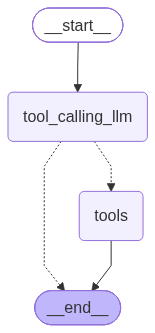

================================ Human Message =================================

What is price of Google stocks?
================================== Ai Message ==================================
Tool Calls:
  stock_price (call_CUgVPOxLOM8F3MtqGLA0R71Y)
 Call ID: call_CUgVPOxLOM8F3MtqGLA0R71Y
  Args:
    name: GOOGL
  stock_price (call_mQ9Buumxr1bhGlS3CdEyCXsA)
 Call ID: call_mQ9Buumxr1bhGlS3CdEyCXsA
  Args:
    name: GOOG
================================= Tool Message =================================
Name: stock_price

[{'type': 'text', 'text': '42.61', 'id': 'lc_706f2459-5e63-4643-9e2a-8f000f268991'}]
================================= Tool Message =================================
Name: stock_price

[{'type': 'text', 'text': '491.38', 'id': 'lc_e487ac46-36a1-4164-a54e-a04f4645af78'}]


In [44]:
import os
from dotenv import load_dotenv
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.graph import MessagesState
from langchain.messages import HumanMessage
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langchain_mcp_adapters.client import MultiServerMCPClient  
from langchain_openai import ChatOpenAI

## Loading OpenAI API key from env file into an environment variable
load_dotenv()
os.environ["OPENAI_API_KEY"] = os.getenv('OPENAI_API_KEY')

## Initialize ChatOpenAI LLM
llm = ChatOpenAI(model="gpt-5-mini")

## Initialize MultiServerMCPClient
client = MultiServerMCPClient(  
    {
        "stock": {
            "transport": "stdio",
            "command": "python",
            "args": ["stock_market_mcp_server.py"],
        },
        "news": {
            "transport": "streamable_http",
            # Ensure your MCP server is running on port 8000
            "url": "http://localhost:8000/mcp",
        }
    }
)

## Get Tools from MCP Servers client is connected to
tools = await client.get_tools()

## Bind List of Tools with LLM
llm_with_tools = llm.bind_tools(tools)
    
## Tool Calling Node
def tool_calling_llm(state: MessagesState):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Initialize StateGraph with MessagesState
graph_builder = StateGraph(MessagesState)

## Add Node to StateGraph
graph_builder.add_node("tool_calling_llm", tool_calling_llm)
graph_builder.add_node("tools", ToolNode(tools))

## Add Edges to StateGraph
graph_builder.add_edge(START, "tool_calling_llm")
graph_builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition,
)
graph_builder.add_edge("tools", END)

## Compile Graph
graph = graph_builder.compile()

## Visualize Graph
display(Image(graph.get_graph().draw_mermaid_png()))

## Invoke Graph
messages = await graph.ainvoke({"messages": HumanMessage(content="What is price of Google stocks?")})

## Print Messages
for m in messages['messages']:
    m.pretty_print()


In [45]:
## Invoke Graph
messages = await graph.ainvoke({"messages": HumanMessage(content="What are market sentiments of Google stocks?")})

## Print Messages
for m in messages['messages']:
    m.pretty_print()


================================ Human Message =================================

What are market sentiments of Google stocks?
================================== Ai Message ==================================
Tool Calls:
  stock_price (call_OHdAA7DUnpEp0NtEqMB098xO)
 Call ID: call_OHdAA7DUnpEp0NtEqMB098xO
  Args:
    name: GOOGL
  get_company_news (call_FEJzej49l9I8ESFFWbMJNrsR)
 Call ID: call_FEJzej49l9I8ESFFWbMJNrsR
  Args:
    company: Alphabet
================================= Tool Message =================================
Name: stock_price

[{'type': 'text', 'text': '123.95', 'id': 'lc_ac16063f-0c88-427f-900c-e57b59dc6eca'}]
================================= Tool Message =================================
Name: get_company_news

[{'type': 'text', 'text': 'Alphabet is performing exceptionally well this quarter. Analysts predict its stock price is likely to rise.', 'id': 'lc_b6e63111-8d79-45ea-9fca-251bd65b5401'}]


# <font color="#800000">ReACT Agents</font>

## <font color="#3366FF">Understanding ReACT Agents</font>

### Implementation Of ReACT Agent

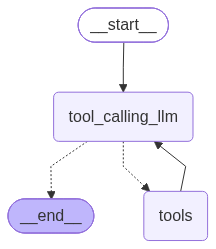

In [40]:
import os
from dotenv import load_dotenv
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.graph import MessagesState
from langchain.messages import HumanMessage
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langchain_mcp_adapters.client import MultiServerMCPClient  
from langchain_openai import ChatOpenAI

## Loading OpenAI API key from env file into an environment variable
load_dotenv()
os.environ["OPENAI_API_KEY"] = os.getenv('OPENAI_API_KEY')

## Initialize ChatOpenAI LLM
llm = ChatOpenAI(model="gpt-5-mini")

## Initialize MultiServerMCPClient
client = MultiServerMCPClient(  
    {
        "stock": {
            "transport": "stdio",
            "command": "python",
            "args": ["stock_market_mcp_server.py"],
        },
        "news": {
            "transport": "streamable_http",
            # Ensure your MCP server is running on port 8000
            "url": "http://localhost:8000/mcp",
        }
    }
)

## Get Tools from MCP Servers client is connected to
tools = await client.get_tools()

## Bind List of Tools with LLM
llm_with_tools = llm.bind_tools(tools)
    
## Tool Calling Node
def tool_calling_llm(state: MessagesState):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Initialize StateGraph with MessagesState
graph_builder = StateGraph(MessagesState)

## Add Node to StateGraph
graph_builder.add_node("tool_calling_llm", tool_calling_llm)
graph_builder.add_node("tools", ToolNode(tools))

## Add Edges to StateGraph
graph_builder.add_edge(START, "tool_calling_llm")
graph_builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition,
)
graph_builder.add_edge("tools", "tool_calling_llm")

## Compile Graph
graph = graph_builder.compile()

## Visualize Graph
display(Image(graph.get_graph().draw_mermaid_png()))


#### Invoke Graph

In [41]:
## Invoke Graph
messages = await graph.ainvoke({"messages": HumanMessage(content="Should I purchase Tesla stocks by selling my 10 stocks of NVIDIA? Please do market analysis and give me recommendation?")})

## Print Messages
for m in messages['messages']:
    m.pretty_print()


================================ Human Message =================================

Should I purchase Tesla stocks by selling my 10 stocks of NVIDIA? Please do market analysis and give me recommendation?
================================== Ai Message ==================================
Tool Calls:
  stock_price (call_Qtn5VEt9o8JkQrgs2ySbAQzQ)
 Call ID: call_Qtn5VEt9o8JkQrgs2ySbAQzQ
  Args:
    name: NVIDIA
  stock_price (call_hqWYWLpGJgBXZ60eFApvK3EI)
 Call ID: call_hqWYWLpGJgBXZ60eFApvK3EI
  Args:
    name: Tesla
  get_company_news (call_cEmbf0Diqysd363iDlrEwSdw)
 Call ID: call_cEmbf0Diqysd363iDlrEwSdw
  Args:
    company: NVIDIA
  get_company_news (call_n6CkFItJE5FQyLJPa3KQxN0N)
 Call ID: call_n6CkFItJE5FQyLJPa3KQxN0N
  Args:
    company: Tesla
================================= Tool Message =================================
Name: stock_price

[{'type': 'text', 'text': '265.2', 'id': 'lc_888610bd-d844-45b6-9870-703e3f1924ee'}]
================================= Tool Message ===============